# Can Quantum Kernels Improve EEG-Based Mental Workload Classification?


## Preprocessing

### Data Loading

Article presenting the dataset, with the acquisition methods and a data analysis: [Lim et al, 2018](https://pubmed.ncbi.nlm.nih.gov/30281467/)

Original Dataset (in EDF format) from: [STEW: Simultaneous Tast EEG Dataset](https://ieee-dataport.org/open-access/stew-simultaneous-task-eeg-workload-dataset)

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)




In [14]:
import os

from huggingface_hub import hf_hub_download

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

In [15]:
REPO_ID = "monster-monash/STEW"

def download_file(filename):
    return hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type="dataset")

X_path = download_file("STEW_X.npy")

Y_path = download_file("STEW_y.csv")

SUBJECT_ID_path = download_file("STEW_subject_id.csv")

X = np.load(X_path)
Y = pd.read_csv(Y_path, header= None).squeeze().to_numpy()
SUBJECT_ID = pd.read_csv(SUBJECT_ID_path, header=None).squeeze().to_numpy()

### Data Exploration

We verify the shapes of the three arrays. 

In [16]:
assert(X.ndim == 3)
assert(X.shape == (28512,14,256)) # Expected shape from the tabular dataset description
assert(len(X)==len(Y)==len(SUBJECT_ID))

We make plots to get a better sense of how the data is structured

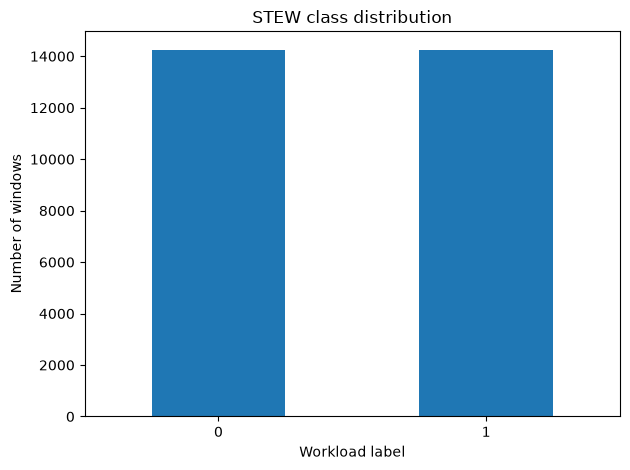

In [17]:
label_counts = pd.Series(Y).value_counts().sort_index()

label_counts.plot(kind="bar")
plt.xlabel("Workload label")
plt.ylabel("Number of windows")
plt.title("STEW class distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

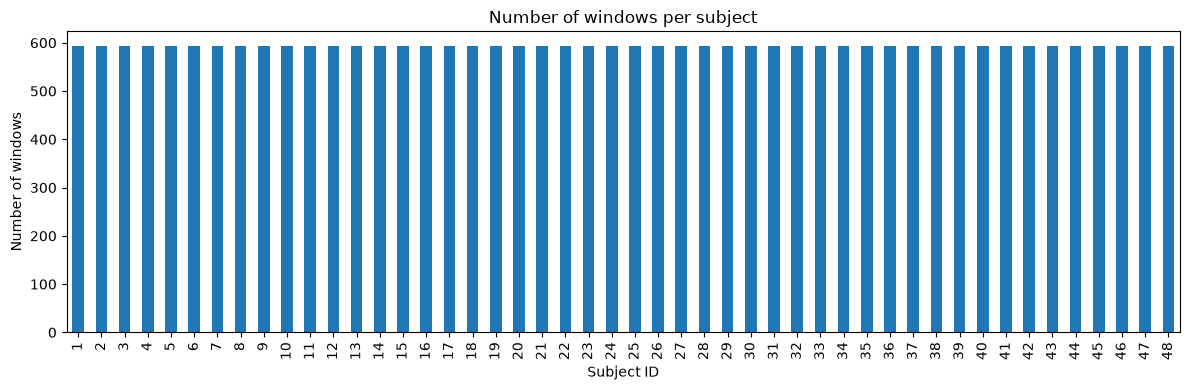

In [18]:
subject_counts = pd.Series(SUBJECT_ID).value_counts().sort_index()

subject_counts.plot(kind="bar", figsize=(12, 4))
plt.xlabel("Subject ID")
plt.ylabel("Number of windows")
plt.title("Number of windows per subject")
plt.tight_layout()
plt.show()

In [19]:
EEG_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
SAMPLING_FREQUENCY = 128 

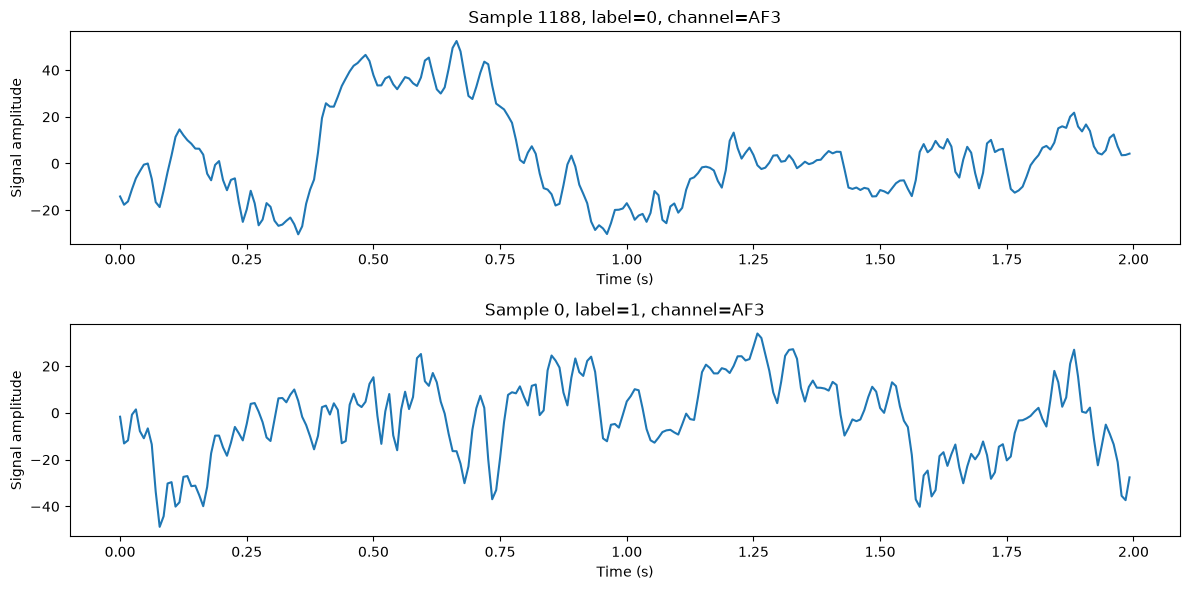

In [20]:
# Find one example for each label
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in np.unique(Y)
]

time = np.arange(X.shape[2]) / SAMPLING_FREQUENCY

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

for ax, idx in zip(axes, sample_indices):
    ax.plot(time, X[idx, 0, :])
    ax.set_title(f"Sample {idx}, label={Y[idx]}, channel={EEG_CHANNELS[0]}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal amplitude")

plt.tight_layout()
plt.show()

We can see that the data is equally divided by workload classes and that the same amount of samples exists for each subject.

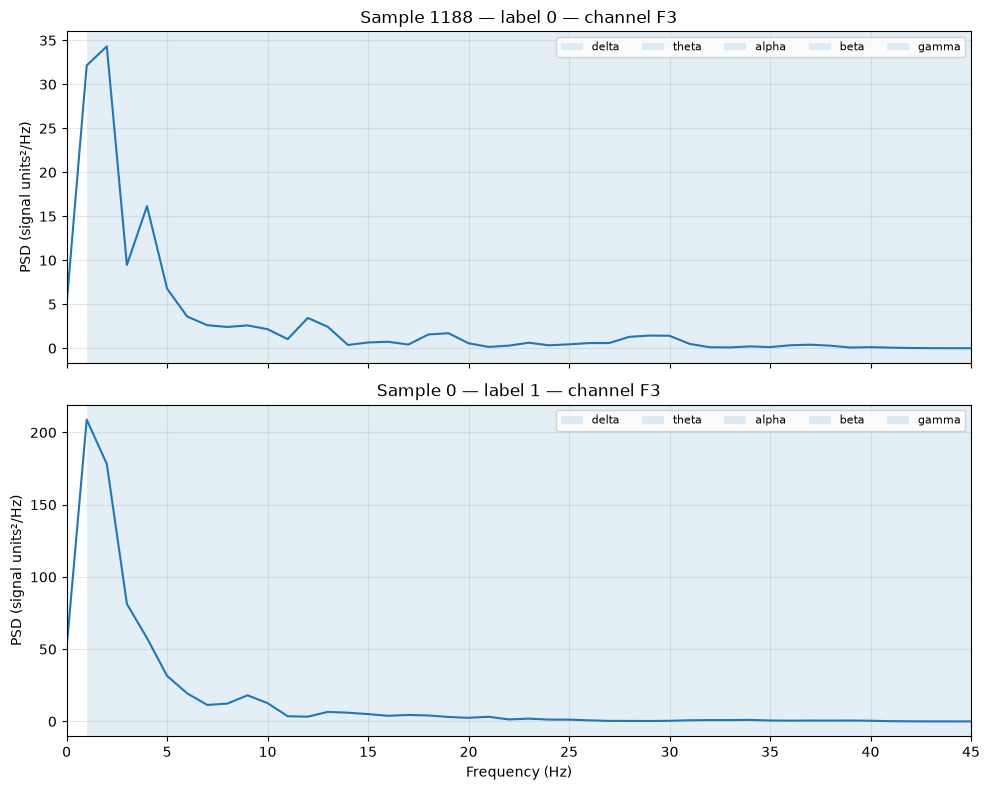

In [24]:
FREQUENCY_BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "beta": (12, 30),
    "gamma": (30, 50),
}

# Find one example window for each class
labels = np.unique(Y)
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in labels
]

# Plot channel F3 for each example
channel_idx = EEG_CHANNELS.index("F4")

fig, axes = plt.subplots(
    len(sample_indices), 1,
    figsize=(10, 4 * len(sample_indices)),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, idx in zip(axes, sample_indices):
    signal = np.asarray(X[idx, channel_idx, :], dtype=float)

    # Welch PSD estimate
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=128,
        noverlap=64
    )

    ax.plot(freqs, psd)
    ax.set_xlim(0, 45)
    ax.set_ylabel("PSD (signal units²/Hz)")
    ax.set_title(f"Sample {idx} — label {Y[idx]} — channel F3")
    ax.grid(True, alpha=0.3)

    # Shade the conventional frequency bands
    for band_name, (low, high) in FREQUENCY_BANDS.items():
        ax.axvspan(low, high, alpha=0.12, label=band_name)

    # Avoid duplicate legend entries
    handles, legend_labels = ax.get_legend_handles_labels()
    unique = dict(zip(legend_labels, handles))
    ax.legend(unique.values(), unique.keys(), ncol=5, fontsize=8)

axes[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

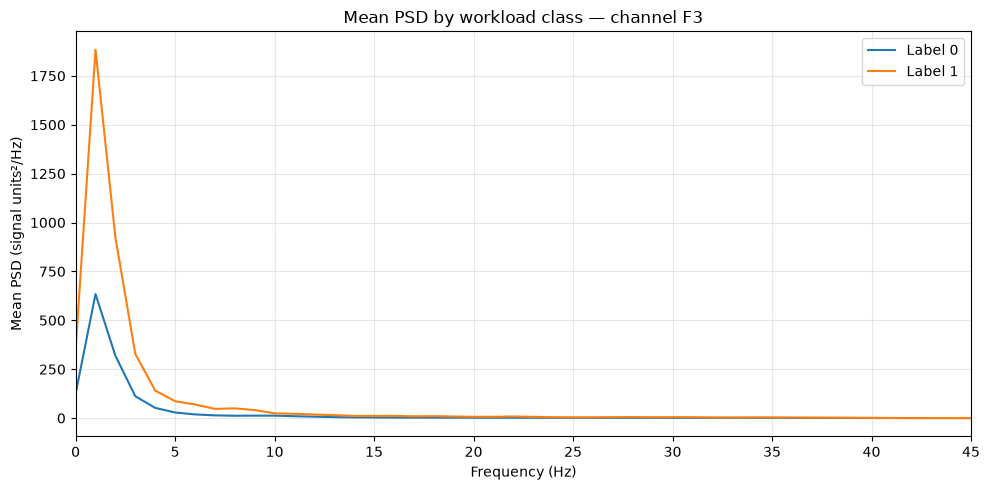

In [ ]:
plt.figure(figsize=(10, 5))

channel_idx = EEG_CHANNELS.index("AF4")

for label in np.unique(y):
    indices = np.flatnonzero(y == label)

    # Average PSD across windows in this class
    psd_list = []

    for idx in indices:
        signal = np.asarray(X[idx, channel_idx, :], dtype=float)

        freqs, psd = welch(
            signal,
            fs=SAMPLING_FREQUENCY,
            nperseg=128,
            noverlap=64
        )

        psd_list.append(psd)

    mean_psd = np.mean(psd_list, axis=0)

    plt.plot(freqs, mean_psd, label=f"Label {label}")

plt.xlim(0, 45)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Mean PSD (signal units²/Hz)")
plt.title("Mean PSD by workload class — channel F3")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Data Cleaning

We remove all the data from subjects 5, 24, 42, as the dataset presentation article (Lim et al, 2018) states that ratings were not obtained for this subjects.


In [ ]:
SUBJECTS_TO_REMOVE=[5,24,42]

mask=np.logical_not(np.isin(SUBJECT_ID,SUBJECTS_TO_REMOVE))
X=X[mask]
Y=Y[mask]
SUBJECT_ID=SUBJECT_ID[mask]

In [ ]:
#We test that the removal was successful
for subject in SUBJECTS_TO_REMOVE:
    assert(X[SUBJECT_ID==subject].size==0)
    assert(Y[SUBJECT_ID==subject].size==0)
    assert(SUBJECT_ID[SUBJECT_ID==subject].size==0)

    assert(X[SUBJECT_ID==(subject-1)].size!=0)
    assert(Y[SUBJECT_ID==(subject-1)].size!=0)
    assert(SUBJECT_ID[SUBJECT_ID==(subject-1)].size!=0)


assert(X.shape == (28512-28512*3/48,14,256)) # Expected new shape, given that we removed 3/48th of the data
assert(len(X)==len(Y)==len(SUBJECT_ID))



### Feature engineering

We crete a .csv table with the chosen features:

In [25]:
def extract_features(signal):

    # Time-domain features
    new_features = {
        "mean": np.mean(signal),
        "std" : np.std(signal),
        "var" : np.var(signal),
        "rms" : np.sqrt(np.mean(signal**2)),
        "skewness": skew(signal, bias=True),
        "kurtosis": kurtosis(signal, fisher=True, bias=True),
    }
    # Frequency-domain features
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=len(signal)
    )

    frequency_resolution = freqs[1] - freqs[0] 

    total_mask = (freqs >= 1) & (freqs < 45)
    total_power = np.sum(psd[total_mask]) * frequency_resolution

    for band, (low, high) in FREQUENCY_BANDS.items():

        mask = (freqs >= low) & (freqs < high)

        power = (
            np.sum(psd[mask]) * frequency_resolution
            if np.any(mask) else 0.0
        )

        new_features[f"{band}_power"] = power

        new_features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 1e-12 else 0.0
        )

    # Spectral entropy over the 1–45 Hz range
    psd_band = psd[total_mask]
    power_sum = psd_band.sum()

    if power_sum > 1e-12:
        probabilities = psd_band / power_sum
        probabilities = probabilities[probabilities > 0]

        new_features["spectral_entropy"] = -np.sum(
            probabilities * np.log2(probabilities)
        )
    else:
        new_features["spectral_entropy"] = 0.0

    return new_features

In [26]:
def create_dataset():
    records = []

    for sample_idx in range(len(X)):

        eeg_sample = X[sample_idx]

        record = {
            "sample_id": sample_idx,
            "subject_id": SUBJECT_ID[sample_idx],
        }

        for channel_idx, channel_name in enumerate(EEG_CHANNELS):

            signal = eeg_sample[channel_idx, :]

            channel_features = extract_features(signal)

            for feature_name, value in channel_features.items():
                column_name = f"{channel_name}_{feature_name}"
                record[column_name] = value

        record["label"] = Y[sample_idx]
        records.append(record)

        if (sample_idx + 1) % 1000 == 0:
            print(f"Processed {sample_idx + 1}/{len(X)} examples")

    print(f"Processed {sample_idx + 1}/{len(X)} examples")
    return records

We create a dataframe with the extracted outputs and write it to a .csv file.

In [27]:
#Run only to create a new extracted feature dataframe (may take a while).
new_dataset=create_dataset()
X_EXT = pd.DataFrame(new_dataset)

Processed 1000/28512 examples
Processed 2000/28512 examples
Processed 3000/28512 examples
Processed 4000/28512 examples
Processed 5000/28512 examples
Processed 6000/28512 examples
Processed 7000/28512 examples
Processed 8000/28512 examples
Processed 9000/28512 examples
Processed 10000/28512 examples
Processed 11000/28512 examples
Processed 12000/28512 examples
Processed 13000/28512 examples
Processed 14000/28512 examples
Processed 15000/28512 examples
Processed 16000/28512 examples
Processed 17000/28512 examples
Processed 18000/28512 examples
Processed 19000/28512 examples
Processed 20000/28512 examples
Processed 21000/28512 examples
Processed 22000/28512 examples
Processed 23000/28512 examples
Processed 24000/28512 examples
Processed 25000/28512 examples
Processed 26000/28512 examples
Processed 27000/28512 examples
Processed 28000/28512 examples
Processed 28512/28512 examples


In [28]:
print(X_EXT.head())
print(X_EXT.shape)

   sample_id  subject_id  AF3_mean    AF3_std     AF3_var    AF3_rms  \
0          0          12 -2.364527  16.718996  279.524841  16.885374   
1          1          12  1.513650  15.534682  241.326355  15.608251   
2          2          12  0.492984  14.909048  222.279709  14.917197   
3          3          12 -2.007783  14.349675  205.913177  14.489458   
4          4          12  1.876135  13.039218  170.021210  13.173500   

   AF3_skewness  AF3_kurtosis  AF3_delta_power  AF3_delta_relative_power  ...  \
0     -0.339354     -0.337851       114.806351                  0.573799  ...   
1     -0.468445     -0.308483       185.131073                  0.716253  ...   
2     -0.283593     -0.254668       141.955475                  0.627093  ...   
3     -0.157667     -0.236524        81.054817                  0.508537  ...   
4     -0.063752     -0.338315        59.304790                  0.397247  ...   

   AF4_theta_power  AF4_theta_relative_power  AF4_alpha_power  \
0       323.099

In [29]:
#Automatically overwrites a file of the same name in this directory.
DATASET_PATH = "STEW_features.csv"
X_EXT.to_csv(DATASET_PATH, index=False)

## Pipelines: Features reduction and Model training

We want to analyze the impact of PCA and ANOVA on two different SVM kernels,  Quantum and RBF and as a guideline, Logistic Regression.

### Hyperparameters

In [ ]:
# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [5, 10, 20, 50, 100]

QUANTUM_KS=[5,10]



# Same SVM hyperparameter grid for a methods, so any difference in score
# comes from the reduction method and not from different SVM settings.
svm_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 0.01, 0.1],
}

# Models hyperparameters:
anova_param_grid = {'anova__k': CANDIDATE_KS, **svm_grid}

# Main metric used to compare the methods
SCORING = 'f1_weighted'

### Train Test Split

In [ ]:
# Separate features, target and subject ids.
# subject_id is NOT a feature, but we keep it as `groups` so that the
# cross-validation never puts the same person in both train and test.
X = X_EXT.drop(columns=['sample_id', 'subject_id', 'label'])
y = X_EXT['label']
groups = X_EXT['subject_id']

# Make sure the data is clean before any modelling
assert X.isna().sum().sum() == 0, "NaN values found in features"
assert all(np.issubdtype(t, np.number) for t in X.dtypes), "Non-numeric columns found"

# Grouped, stratified CV: no subject appears in both train and validation folds.
# The same object is used for both methods, so they see identical splits.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Pipelines

In [ ]:
# All reducers
reducers = {
    "ANOVA": (
        SelectKBest(score_func=f_classif),
        {"reducer__k": CANDIDATE_KS},
    ),
    "PCA": (
        PCA(),
        {"reducer__n_components": CANDIDATE_KS},
    ),
}

In [ ]:
# Preparing quantum kernel
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC

quantum_feature_map = zz_feature_map(
    feature_dimension=4,
    reps=2,
    entanglement="linear",
)

quantum_kernel = FidelityQuantumKernel(
    feature_map=quantum_feature_map
)

In [ ]:
# All classifiers
classifiers = {
    "SVM": (
        SVC(),
        {
            "classifier__kernel": ["rbf"],
            "classifier__C": [0.1, 1, 10, 100],
            "classifier__gamma": ["scale", 0.01, 0.1, 1],
        },
    ),
    "Quantum SVM": (
        QSVC(quantum_kernel=quantum_kernel),
        {
            "classifier__C": [0.1, 1, 10, 100],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {
            "classifier__C": [0.1, 1, 10, 100],
        },
    ),
}

In [ ]:
searches = {}
results = []

for reducer_name, (reducer, reducer_grid) in reducers.items():
    for classifier_name, (classifier, classifier_grid) in classifiers.items():
        name = f"{reducer_name} + {classifier_name}"

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("reducer", reducer),
            ("classifier", classifier),
        ])

        param_grid = {
            **reducer_grid,
            **classifier_grid,
        }

        print(f"\nExecuting GridSearchCV: {name}")

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=-1,
            verbose=1,
        )

        search.fit(X, y, groups=groups)

        searches[name] = search

        results.append({
            "Model": name,
            "Best CV F1-weighted": search.best_score_,
            "Best parameters": search.best_params_,
        })

        print(f"- Best score: {search.best_score_:.4f}")
        print(f"- Best parameters: {search.best_params_}")


Executing GridSearchCV: ANOVA + SVM
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7372
- Best parameters: {'classifier__C': 1, 'classifier__kernel': 'rbf', 'reducer__k': 50}

Executing GridSearchCV: ANOVA + Quantum SVM
Fitting 5 folds for each of 20 candidates, totalling 100 fits


ValueError: 
All the 100 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\vsf24\AppData\Local\Programs\Python\Python314\Lib\site-packages\qiskit_machine_learning\kernels\base_kernel.py", line 117, in _validate_input
    self._feature_map.num_qubits = x_vec.shape[1]
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: property 'num_qubits' of 'QuantumCircuit' object has no setter

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "c:\Users\vsf24\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^

## Scoring

In [ ]:
comparison_results = []

for name, search in searches.items():

    cv_results = pd.DataFrame(search.cv_results_)

    # Identify the dimensionality parameter:
    # ANOVA uses reducer__k, PCA uses reducer__n_components.
    dim_param = (
        "param_reducer__k"
        if "param_reducer__k" in cv_results.columns
        else "param_reducer__n_components"
    )

    # For each dimensionality, keep the best classifier hyperparameters.
    best_by_dim = (
        cv_results.loc[
            cv_results.groupby(dim_param)["mean_test_score"].idxmax()
        ]
        .sort_values(dim_param)
    )

    for _, row in best_by_dim.iterrows():
        comparison_results.append({
            "Model": name,
            "k": int(row[dim_param]),
            "F1_mean": row["mean_test_score"],
            "F1_std": row["std_test_score"],
            "Best_params": row["params"],
        })

# Detailed results: one row per model and dimensionality.
results_df = (
    pd.DataFrame(comparison_results)
    .sort_values(["Model", "k"])
    .reset_index(drop=True)
)

# Save detailed results for reuse in the merged notebook.
results_df.to_csv("all_models_f1_by_dimension.csv", index=False)

# Summary: best overall CV score for each of the six pipelines.
best_results_df = (
    results_df.loc[results_df.groupby("Model")["F1_mean"].idxmax()]
    .sort_values("F1_mean", ascending=False)
    .reset_index(drop=True)
)

best_results_df.to_csv("best_results_by_model.csv", index=False)

# Display both tables in JupyterLab.
display(results_df)
display(best_results_df)

,Model,k,F1_mean,F1_std,Best_params
0,ANOVA + Logistic Regression,5,0.635026,0.022085,"{'classifier__C': 1, 'reducer__k': 5}"
1,ANOVA + Logistic Regression,10,0.671060,0.020469,"{'classifier__C': 0.1, 'reducer__k': 10}"
2,ANOVA + Logistic Regression,20,0.688482,0.040150,"{'classifier__C': 100, 'reducer__k': 20}"
3,ANOVA + Logistic Regression,50,0.719321,0.056838,"{'classifier__C': 0.1, 'reducer__k': 50}"
4,ANOVA + Logistic Regression,100,0.725595,0.055757,"{'classifier__C': 10, 'reducer__k': 100}"
5,ANOVA + SVM,5,0.648916,0.019028,"{'classifier__C': 10, 'classifier__kernel': 'r..."
6,ANOVA + SVM,10,0.691149,0.020853,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
7,ANOVA + SVM,20,0.703304,0.034461,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
8,ANOVA + SVM,50,0.747133,0.042214,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
9,ANOVA + SVM,100,0.745820,0.043268,"{'classifier__C': 1, 'classifier__kernel': 'rb..."


,Model,k,F1_mean,F1_std,Best_params
0,ANOVA + SVM,50,0.747133,0.042214,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
1,PCA + SVM,100,0.734829,0.046595,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
2,PCA + Logistic Regression,100,0.728227,0.032351,"{'classifier__C': 10, 'reducer__n_components':..."
3,ANOVA + Logistic Regression,100,0.725595,0.055757,"{'classifier__C': 10, 'reducer__k': 100}"


## Plotting

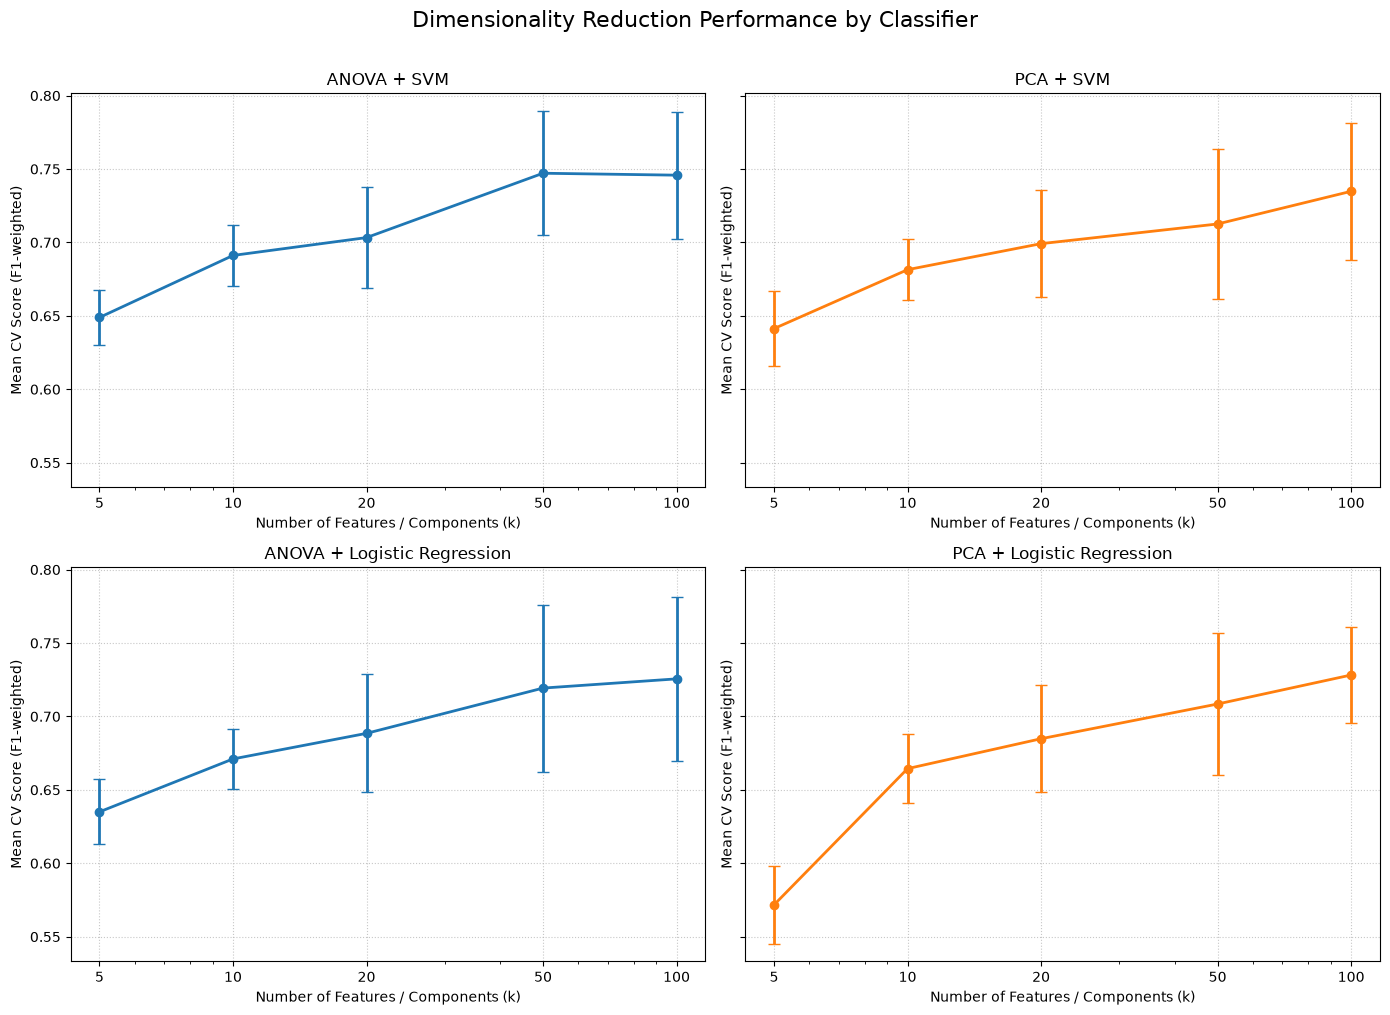

In [ ]:
classifier_names = list(classifiers.keys())
reducer_names = list(reducers.keys())

n_rows = len(classifier_names)
n_cols = len(reducer_names)

# Generate one color per reducer.
cmap = plt.get_cmap("tab10")
colors = {
    name: cmap(i % cmap.N)
    for i, name in enumerate(reducer_names)
}

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(7 * n_cols, 5 * n_rows),
    sharey=True,
    squeeze=False
)

for row, classifier_name in enumerate(classifier_names):

    for col, reducer_name in enumerate(reducer_names):

        ax = axes[row, col]
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = (
            results_df[results_df["Model"] == model_name]
            .sort_values("k")
        )

        if model_results.empty:
            ax.set_title(f"{reducer_name} + {classifier_name} (no results)")
            continue

        ax.errorbar(
            model_results["k"],
            model_results["F1_mean"],
            yerr=model_results["F1_std"],
            marker="o",
            color=colors[reducer_name],
            linewidth=2,
            capsize=4
        )

        ax.set_xscale("log")
        ax.set_xticks(model_results["k"])
        ax.set_xticklabels(model_results["k"])

        ax.set_title(f"{reducer_name} + {classifier_name}")
        ax.set_xlabel("Number of Features / Components (k)")
        ax.set_ylabel("Mean CV Score (F1-weighted)")
        ax.grid(True, linestyle=":", alpha=0.7)

fig.suptitle(
    "Dimensionality Reduction Performance by Classifier",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.savefig(
    "reduction_comparison_by_classifier.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## Analysis